Generar 100 muestras aleatorias de ciirdenadas (x, y)  sobre una recta y = mx + b, con ruido o dispersion. Pintar los puntos x, y generados

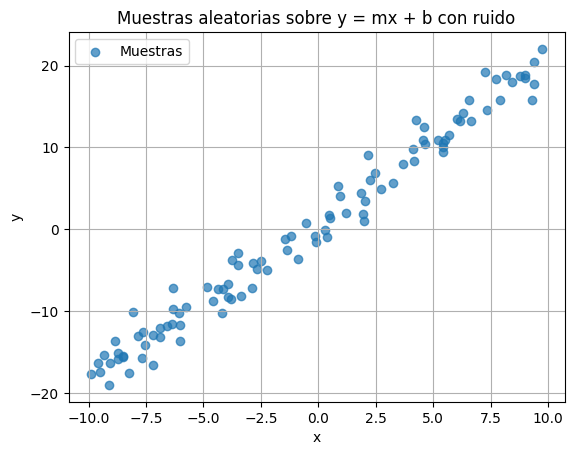

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

m = 2
b = 1
n = 100
ruido = 2

x = np.random.uniform(-10, 10, n)
y = m * x + b + np.random.normal(0, ruido, n)

plt.scatter(x, y, alpha=0.7, label="Muestras")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Muestras aleatorias sobre y = mx + b con ruido")
plt.grid(True)
plt.legend()
plt.show()

Usar una neurona artificial de 5 entradas, de forma iterativa, para encontrar los mejores Wi que acercan Yestimado al YYgenerado. Usar como funcion de activacion, on/off

v = f(sum(Wi * Xi))

Se espera que falle

Época 0: errores = 12
Época 10: errores = 4
Época 20: errores = 4
Época 30: errores = 4
Época 40: errores = 4
Época 50: errores = 4
Época 60: errores = 4
Época 70: errores = 4
Época 80: errores = 4
Época 90: errores = 4

Pesos finales: [0.08238731 0.01456942 0.01986323 0.01043174 0.01      ]
Exactitud binaria: 0.96
Error cuadrático frente a y continua: 127.5856387228714


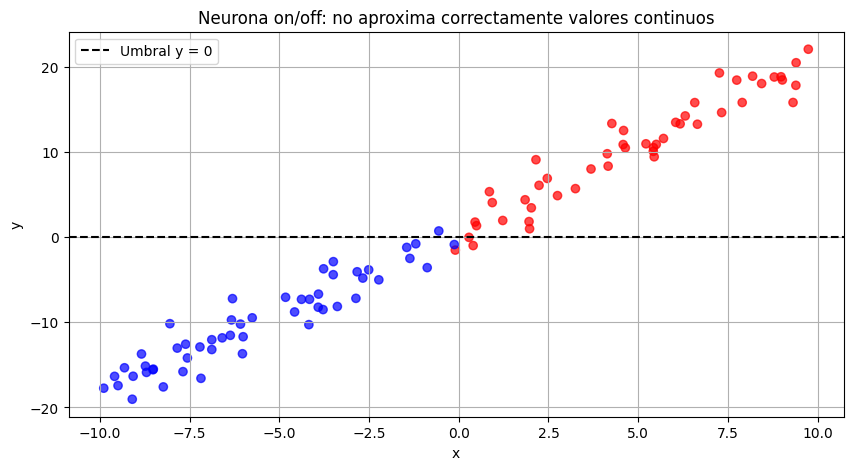

In [2]:
# La activación on/off solo puede producir 0 o 1, por lo que no puede
# aproximar directamente los valores continuos de y.

# Cinco entradas: x, x², x³, sin(x) y una entrada constante para el sesgo
X = np.column_stack([
    x,
    x**2,
    x**3,
    np.sin(x),
    np.ones_like(x)
])

# Normalización para mejorar la estabilidad del entrenamiento
X[:, :4] = (X[:, :4] - X[:, :4].mean(axis=0)) / X[:, :4].std(axis=0)

# Objetivo binario compatible con la función on/off
objetivo = (y >= 0).astype(int)

pesos = np.zeros(5)
tasa_aprendizaje = 0.01
epocas = 100

for epoca in range(epocas):
    errores = 0

    for xi, yi in zip(X, objetivo):
        suma = np.dot(pesos, xi)
        y_estimado = int(suma >= 0)

        error = yi - y_estimado
        pesos += tasa_aprendizaje * error * xi
        errores += abs(error)

    if epoca % 10 == 0:
        print(f"Época {epoca}: errores = {errores}")

prediccion_binaria = (X @ pesos >= 0).astype(int)

print("\nPesos finales:", pesos)
print("Exactitud binaria:", np.mean(prediccion_binaria == objetivo))
print("Error cuadrático frente a y continua:",
      np.mean((prediccion_binaria - y) ** 2))

plt.figure(figsize=(10, 5))
plt.scatter(x, y, c=prediccion_binaria, cmap="bwr", alpha=0.7)
plt.axhline(0, color="black", linestyle="--", label="Umbral y = 0")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Neurona on/off: no aproxima correctamente valores continuos")
plt.grid(True)
plt.legend()
plt.show()

En el punto anterior incluir como funcion de costo el MSE (Yreal vs Y est), cambiar a funcion de activacion sigmoide. Incluir offset y repetir la estimacion de la recta. Proporcionar los mejores Wi

Mejores pesos Wi, incluido el offset:
W1 = 1.093822
W2 = 0.041406
W3 = 0.431065
W4 = 0.006931
offset = -0.212507

MSE en la escala original: 3.072092


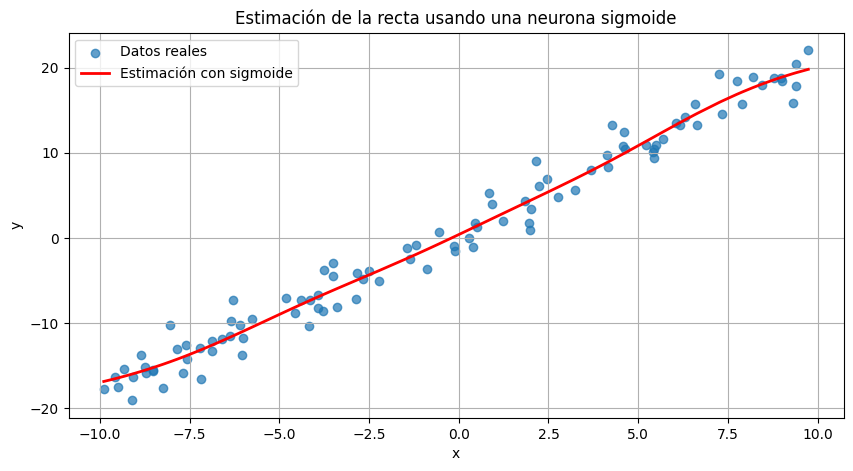

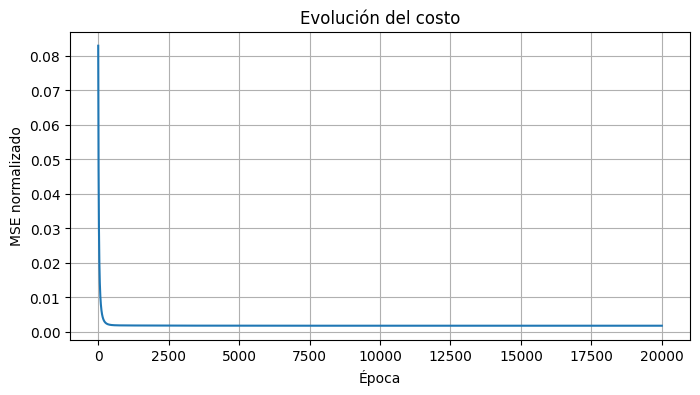

In [3]:
# La última columna de X es el offset: X[:, -1] = 1

# Escalar y al intervalo [0, 1], necesario para usar sigmoide
y_min, y_max = y.min(), y.max()
y_normalizada = (y - y_min) / (y_max - y_min)

pesos_sigmoide = np.zeros(X.shape[1])
tasa_aprendizaje_sigmoide = 0.1
epocas_sigmoide = 20000
historial_mse = []

def sigmoide(z):
    z = np.clip(z, - estado_maximo, estado_maximo)
    return 1 / (1 + np.exp(-z))

estado_maximo = 50

for _ in range(epocas_sigmoide):
    z = X @ pesos_sigmoide
    salida = sigmoide(z)

    error = salida - y_normalizada
    mse = np.mean(error ** 2)
    historial_mse.append(mse)

    # Gradiente del MSE respecto a los pesos
    gradiente = (2 / len(y)) * (X.T @ (error * salida * (1 - salida)))
    pesos_sigmoide -= tasa_aprendizaje_sigmoide * gradiente

# Convertir la salida de la sigmoide nuevamente a la escala original
y_estimado_sigmoide = y_min + sigmoide(X @ pesos_sigmoide) * (y_max - y_min)
mse_original = np.mean((y - y_estimado_sigmoide) ** 2)

print("Mejores pesos Wi, incluido el offset:")
for i, peso in enumerate(pesos_sigmoide):
    nombre = "offset" if i == X.shape[1] - 1 else f"W{i + 1}"
    print(f"{nombre} = {peso:.6f}")

print(f"\nMSE en la escala original: {mse_original:.6f}")

plt.figure(figsize=(10, 5))
plt.scatter(x, y, alpha=0.7, label="Datos reales")
orden = np.argsort(x)
plt.plot(x[orden], y_estimado_sigmoide[orden],
         color="red", linewidth=2, label="Estimación con sigmoide")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Estimación de la recta usando una neurona sigmoide")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(historial_mse)
plt.xlabel("Época")
plt.ylabel("MSE normalizado")
plt.title("Evolución del costo")
plt.grid(True)
plt.show()

Entrenar una ANN para clasificar elementos de WINE dataset, hacer cross validation, split 70/30, usar f -> sigmoide, funcion de costo -> error, mostrar frontera y resultado
Se debe tener 3 salidas, en este caso, 3 neuronas. Se recomienda tener una red neuronal de  13 entradas. Se deben concetar todas las entradas a las neuronas y hacerlo de forma iterativa para estimar los Wi que permiten diferneciar los vinos. Poner metricas de desempeño.

Matriz de confusion.

Métricas sobre el conjunto de prueba
Exactitud : 0.9815
Precisión : 0.9825
Recall    : 0.9841
F1-score  : 0.9829

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        18
           1       1.00      0.95      0.98        21
           2       1.00      1.00      1.00        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54

Matriz de confusión:
[[18  0  0]
 [ 1 20  0]
 [ 0  0 15]]
Exactitud de cada fold: [0.9722222222222222, 0.9722222222222222, 0.9722222222222222, 1.0, 1.0]
Exactitud media CV: 0.9833
Desviación estándar CV: 0.0136


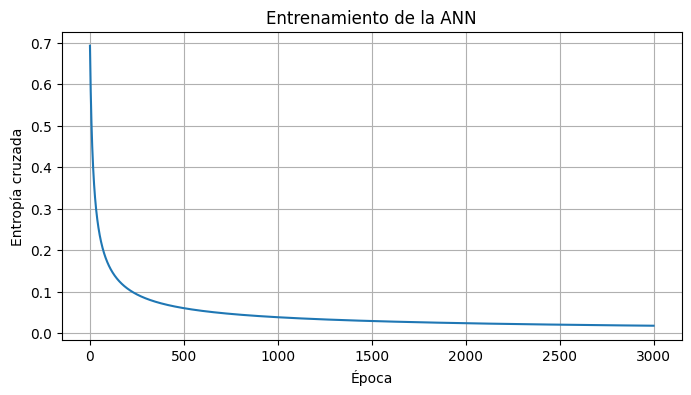

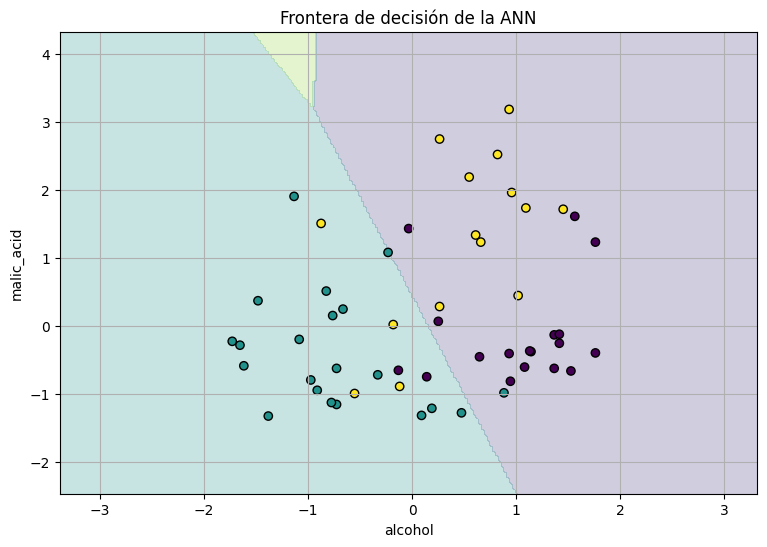


Pesos finales de las 13 entradas y offset:
alcohol: [ 1.77515093 -2.17537061  0.48500318]
malic_acid: [ 0.53326592 -0.82881432  0.55695888]
ash: [ 1.14348322 -1.66227817  0.73396237]
alcalinity_of_ash: [-2.00974522  1.32953822  0.31146391]
magnesium: [ 2.25477229e-01 -4.95875090e-01 -3.44758649e-04]
total_phenols: [ 0.61169235 -0.34232736 -0.13168387]
flavanoids: [ 1.56683636  0.41646149 -1.71532192]
nonflavanoid_phenols: [ 0.22250284  0.11642384 -0.25703867]
proanthocyanins: [-0.59961563  0.97573699 -0.71367504]
color_intensity: [ 0.10686898 -2.06316874  1.80110653]
hue: [-0.09782726  1.46868602 -1.41988316]
od280/od315_of_diluted_wines: [ 1.08602414  0.03943296 -0.93593203]
proline: [ 2.27907523 -2.30598667  0.03805211]
Offset: [-1.88431065 -1.27358177 -3.17433486]


In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Datos: 13 entradas y 3 clases
X_wine = wine.data
y_wine = wine.target
n_clases = len(np.unique(y_wine))

X_train, X_test, y_train, y_test = train_test_split(
    X_wine, y_wine,
    test_size=0.30,
    stratify=y_wine,
    random_state=42
)

escalador_ann = StandardScaler()
X_train_std = escalador_ann.fit_transform(X_train)
X_test_std = escalador_ann.transform(X_test)

def sigmoide_ann(z):
    z = np.clip(z, -50, 50)
    return 1 / (1 + np.exp(-z))

def entrenar_ann(X, y, epocas=3000, tasa=0.05):
    X_bias = np.c_[X, np.ones(X.shape[0])]
    Y = np.eye(n_clases)[y]

    pesos = np.zeros((X_bias.shape[1], n_clases))
    historial_error = []

    for _ in range(epocas):
        z = X_bias @ pesos
        salida = sigmoide_ann(z)

        # Entropía cruzada binaria para las tres salidas sigmoidales
        salida_segura = np.clip(salida, 1e-9, 1 - 1e-9)
        error = -np.mean(
            Y * np.log(salida_segura) +
            (1 - Y) * np.log(1 - salida_segura)
        )
        historial_error.append(error)

        gradiente = (X_bias.T @ (salida - Y)) / len(y)
        pesos -= tasa * gradiente

    return pesos, historial_error

def predecir_ann(X, pesos):
    X_bias = np.c_[X, np.ones(X.shape[0])]
    probabilidades = sigmoide_ann(X_bias @ pesos)
    return np.argmax(probabilidades, axis=1), probabilidades

# Entrenamiento 70/30
pesos_ann, historial_error_ann = entrenar_ann(
    X_train_std, y_train
)

pred_train, probabilidades_train = predecir_ann(X_train_std, pesos_ann)
pred_test, probabilidades_test = predecir_ann(X_test_std, pesos_ann)

print("Métricas sobre el conjunto de prueba")
print(f"Exactitud : {accuracy_score(y_test, pred_test):.4f}")
print(f"Precisión : {precision_score(y_test, pred_test, average='macro'):.4f}")
print(f"Recall    : {recall_score(y_test, pred_test, average='macro'):.4f}")
print(f"F1-score  : {f1_score(y_test, pred_test, average='macro'):.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, pred_test))

matriz_confusion = confusion_matrix(y_test, pred_test)
print("Matriz de confusión:")
print(matriz_confusion)

# Validación cruzada estratificada
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados_cv_ann = []

for indices_entrenamiento, indices_validacion in skf.split(X_wine, y_wine):
    X_cv_train = X_wine[indices_entrenamiento]
    X_cv_valid = X_wine[indices_validacion]
    y_cv_train = y_wine[indices_entrenamiento]
    y_cv_valid = y_wine[indices_validacion]

    escalador_cv = StandardScaler()
    X_cv_train = escalador_cv.fit_transform(X_cv_train)
    X_cv_valid = escalador_cv.transform(X_cv_valid)

    pesos_cv_ann, _ = entrenar_ann(X_cv_train, y_cv_train)
    pred_cv, _ = predecir_ann(X_cv_valid, pesos_cv_ann)

    resultados_cv_ann.append(accuracy_score(y_cv_valid, pred_cv))

print("Exactitud de cada fold:", resultados_cv_ann)
print(f"Exactitud media CV: {np.mean(resultados_cv_ann):.4f}")
print(f"Desviación estándar CV: {np.std(resultados_cv_ann):.4f}")

# Evolución del error
plt.figure(figsize=(8, 4))
plt.plot(historial_error_ann)
plt.xlabel("Época")
plt.ylabel("Entropía cruzada")
plt.title("Entrenamiento de la ANN")
plt.grid(True)
plt.show()

# Frontera de decisión usando las dos primeras características.
# Las otras 11 características se fijan en su media estandarizada.
x1_min, x1_max = X_train_std[:, 0].min() - 1, X_train_std[:, 0].max() + 1
x2_min, x2_max = X_train_std[:, 1].min() - 1, X_train_std[:, 1].max() + 1

frontera_x1, frontera_x2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 250),
    np.linspace(x2_min, x2_max, 250)
)

malla_ann = np.zeros((frontera_x1.size, X_train_std.shape[1]))
malla_ann[:, 0] = frontera_x1.ravel()
malla_ann[:, 1] = frontera_x2.ravel()

pred_frontera, _ = predecir_ann(malla_ann, pesos_ann)
pred_frontera = pred_frontera.reshape(frontera_x1.shape)

plt.figure(figsize=(9, 6))
plt.contourf(
    frontera_x1, frontera_x2, pred_frontera,
    levels=np.arange(n_clases + 1) - 0.5,
    alpha=0.25, cmap="viridis"
)
plt.scatter(
    X_test_std[:, 0], X_test_std[:, 1],
    c=y_test, edgecolor="black", cmap="viridis"
)
plt.xlabel(wine.feature_names[0])
plt.ylabel(wine.feature_names[1])
plt.title("Frontera de decisión de la ANN")
plt.grid(True)
plt.show()

print("\nPesos finales de las 13 entradas y offset:")
for i, nombre in enumerate(wine.feature_names):
    print(f"{nombre}: {pesos_ann[i]}")
print("Offset:", pesos_ann[-1])

Implementar para el ejercicio anteriior un MLP (Multi Layer Perceptron) entrenarloo y mostrar matriz de confusion, comparar resultados con el previo.

Resultados del MLP sobre el conjunto de prueba
Exactitud : 0.9630
Precisión : 0.9619
Recall    : 0.9619
F1-score  : 0.9619

Reporte de clasificación del MLP:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       0.95      0.95      0.95        21
           2       0.93      0.93      0.93        15

    accuracy                           0.96        54
   macro avg       0.96      0.96      0.96        54
weighted avg       0.96      0.96      0.96        54

Matriz de confusión del MLP:
[[18  0  0]
 [ 0 20  1]
 [ 0  1 14]]

Validación cruzada del MLP:
Exactitud de cada fold: [0.9722222222222222, 0.9722222222222222, 0.9722222222222222, 1.0, 1.0]
Exactitud media CV: 0.9833
Desviación estándar CV: 0.0136

Comparación de modelos:
{'Modelo': ['ANN sigmoidal', 'MLP'], 'Exactitud prueba': [0.9814814814814815, 0.9629629629629629], 'Exactitud media CV': [np.float64(0.9833333333333332), np.float64(0.9833333333333332)], '

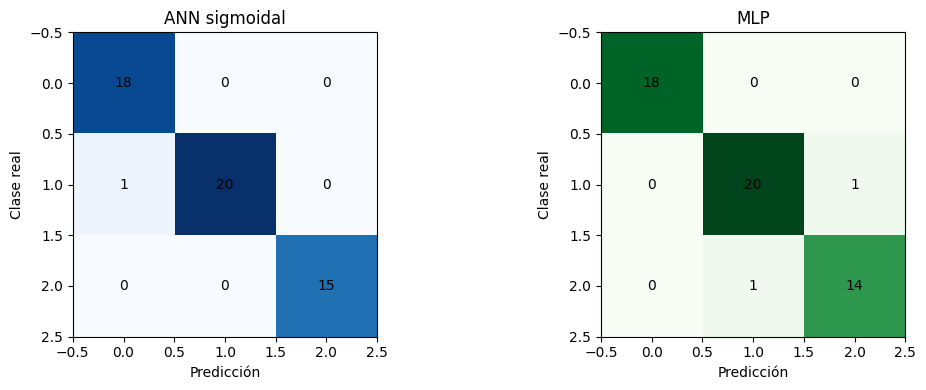

In [9]:
from sklearn.neural_network import MLPClassifier

# MLP con una capa oculta de 10 neuronas y activación sigmoide
mlp = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation="logistic",
    solver="lbfgs",
    max_iter=3000,
    random_state=42
)

# Entrenamiento y evaluación usando el mismo split 70/30
mlp.fit(X_train_std, y_train)

pred_test_mlp = mlp.predict(X_test_std)
probabilidades_test_mlp = mlp.predict_proba(X_test_std)

print("Resultados del MLP sobre el conjunto de prueba")
print(f"Exactitud : {accuracy_score(y_test, pred_test_mlp):.4f}")
print(f"Precisión : {precision_score(y_test, pred_test_mlp, average='macro'):.4f}")
print(f"Recall    : {recall_score(y_test, pred_test_mlp, average='macro'):.4f}")
print(f"F1-score  : {f1_score(y_test, pred_test_mlp, average='macro'):.4f}")

print("\nReporte de clasificación del MLP:")
print(classification_report(y_test, pred_test_mlp))

matriz_confusion_mlp = confusion_matrix(y_test, pred_test_mlp)
print("Matriz de confusión del MLP:")
print(matriz_confusion_mlp)

# Validación cruzada del MLP
resultados_cv_mlp = []

for indices_entrenamiento, indices_validacion in skf.split(X_wine, y_wine):
    X_cv_train = X_wine[indices_entrenamiento]
    X_cv_valid = X_wine[indices_validacion]
    y_cv_train = y_wine[indices_entrenamiento]
    y_cv_valid = y_wine[indices_validacion]

    escalador_mlp_cv = StandardScaler()
    X_cv_train = escalador_mlp_cv.fit_transform(X_cv_train)
    X_cv_valid = escalador_mlp_cv.transform(X_cv_valid)

    mlp_cv = MLPClassifier(
        hidden_layer_sizes=(10,),
        activation="logistic",
        solver="lbfgs",
        max_iter=3000,
        random_state=42
    )

    mlp_cv.fit(X_cv_train, y_cv_train)
    pred_cv_mlp = mlp_cv.predict(X_cv_valid)
    resultados_cv_mlp.append(
        accuracy_score(y_cv_valid, pred_cv_mlp)
    )

print("\nValidación cruzada del MLP:")
print("Exactitud de cada fold:", resultados_cv_mlp)
print(f"Exactitud media CV: {np.mean(resultados_cv_mlp):.4f}")
print(f"Desviación estándar CV: {np.std(resultados_cv_mlp):.4f}")

# Comparación con la neurona ANN anterior
comparacion = {
    "Modelo": ["ANN sigmoidal", "MLP"],
    "Exactitud prueba": [
        accuracy_score(y_test, pred_test),
        accuracy_score(y_test, pred_test_mlp)
    ],
    "Exactitud media CV": [
        np.mean(resultados_cv_ann),
        np.mean(resultados_cv_mlp)
    ],
    "F1-score prueba": [
        f1_score(y_test, pred_test, average="macro"),
        f1_score(y_test, pred_test_mlp, average="macro")
    ]
}

print("\nComparación de modelos:")
print(comparacion)

# Comparación visual de matrices de confusión
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].imshow(confusion_matrix(y_test, pred_test), cmap="Blues")
ejes[0].set_title("ANN sigmoidal")
ejes[0].set_xlabel("Predicción")
ejes[0].set_ylabel("Clase real")

ejes[1].imshow(matriz_confusion_mlp, cmap="Greens")
ejes[1].set_title("MLP")
ejes[1].set_xlabel("Predicción")
ejes[1].set_ylabel("Clase real")

for eje, matriz in zip(
    ejes, [confusion_matrix(y_test, pred_test), matriz_confusion_mlp]
):
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            eje.text(j, i, matriz[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()